<a href="https://www.kaggle.com/code/noir1112/optimrl-trading-experiment?scriptVersionId=247428630" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
! pip install optimrl

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import torch.nn as nn
import torch.optim as optim
import optimrl
import matplotlib.pyplot as plt
from IPython.display import clear_output
%matplotlib inline

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/stock-market-dataset/symbols_valid_meta.csv
/kaggle/input/stock-market-dataset/stocks/MTL.csv
/kaggle/input/stock-market-dataset/stocks/JOE.csv
/kaggle/input/stock-market-dataset/stocks/DRE.csv
/kaggle/input/stock-market-dataset/stocks/CTY.csv
/kaggle/input/stock-market-dataset/stocks/AMSF.csv
/kaggle/input/stock-market-dataset/stocks/IMH.csv
/kaggle/input/stock-market-dataset/stocks/GFL.csv
/kaggle/input/stock-market-dataset/stocks/CLM.csv
/kaggle/input/stock-market-dataset/stocks/UBER.csv
/kaggle/input/stock-market-dataset/stocks/NEBU.csv
/kaggle/input/stock-market-dataset/stocks/SGB.csv
/kaggle/input/stock-market-dataset/stocks/WWW.csv
/kaggle/input/stock-market-dataset/stocks/UTSI.csv
/kaggle/input/stock-market-dataset/stocks/PBB.csv
/kaggle/input/stock-market-dataset/stocks/UFCS.csv
/kaggle/input/stock-market-dataset/stocks/ZM.csv
/kaggle/input/stock-market-dataset/stocks/DCPH.csv
/kaggle/input/stock-market-dataset/stocks/HALL.csv
/kaggle/input/stock-market-dataset/s

In [3]:
class TradingEnv:
    def __init__(self, prices, window_size=10, initial_balance=1000):
        """
        prices: 1D numpy array of closing prices.
        window_size: number of steps used to form the state.
        initial_balance: starting cash for the agent.
        """
        self.prices = prices
        self.window_size = window_size
        self.initial_balance = initial_balance
        self.reset()
        
    def reset(self):
        self.balance = self.initial_balance
        self.shares_held = 0
        self.current_step = self.window_size
        self.portfolio_values = [self.initial_balance]  # Track portfolio value over time
        return self.prices[self.current_step - self.window_size:self.current_step]
    
    def step(self, action):
        """
        Actions:
            0: Hold
            1: Buy one share (if enough balance)
            2: Sell one share (if any are held)
        """
        current_price = self.prices[self.current_step]
        
        if action == 1:  # Buy one share
            if self.balance >= current_price:
                self.balance -= current_price
                self.shares_held += 1
        elif action == 2:  # Sell one share
            if self.shares_held > 0:
                self.shares_held -= 1
                self.balance += current_price
        
        self.current_step += 1
        done = (self.current_step >= len(self.prices))
        
        next_state = (
            self.prices[self.current_step - self.window_size:self.current_step]
            if not done else None
        )
        
        portfolio_value = self.balance + self.shares_held * current_price
        self.portfolio_values.append(portfolio_value)
        reward = portfolio_value - self.initial_balance
        
        return next_state, reward, done
    
    def render(self):
        """Visualize the portfolio value over time"""
        plt.figure(figsize=(10, 5))
        plt.plot(self.portfolio_values)
        plt.title('Portfolio Value Over Time')
        plt.xlabel('Steps')
        plt.ylabel('Portfolio Value ($)')
        plt.grid(True)
        plt.show()

In [4]:
class PolicyNetwork(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.Tanh(),
            nn.Linear(64, output_dim),
            nn.LogSoftmax(dim=-1)
        )
    
    def forward(self, x):
        return self.network(x)

In [5]:
def train_agent(df, epochs=10, episodes_per_epoch=5, window_size=10, initial_balance=1000):
    # Use the closing prices as the time series input
    prices = df['Close'].values.astype(np.float32)
    
    # Create the trading environment
    env = TradingEnv(prices, window_size=window_size, initial_balance=initial_balance)
    
    input_dim = window_size
    output_dim = 3    # three possible actions: hold, buy, sell
    
    policy = PolicyNetwork(input_dim, output_dim)
    reference_policy = PolicyNetwork(input_dim, output_dim)
    reference_policy.load_state_dict(policy.state_dict())
    
    optimizer = optim.Adam(policy.parameters(), lr=1e-3)
    grpo = optimrl.GRPO(epsilon=0.2, beta=0.1)
    
    # Track metrics
    epoch_rewards = []
    portfolio_histories = []
    
    for epoch in range(epochs):
        episode_rewards = []
        
        for ep in range(episodes_per_epoch):
            state = env.reset()
            done = False
            
            log_probs_old_list = []
            log_probs_ref_list = []
            rewards_list = []
            states_list = []
            actions_list = []
            
            while not done:
                state_tensor = torch.from_numpy(state).float().unsqueeze(0)
                
                log_probs_current = policy(state_tensor)
                log_probs_reference = reference_policy(state_tensor)
                
                probs = torch.exp(log_probs_current)
                m = torch.distributions.Categorical(probs)
                action = m.sample().item()
                
                log_prob_current = log_probs_current[0, action].item()
                log_prob_reference = log_probs_reference[0, action].item()
                log_probs_old_list.append(log_prob_current)
                log_probs_ref_list.append(log_prob_reference)
                states_list.append(state)
                actions_list.append(action)
                
                next_state, reward, done = env.step(action)
                rewards_list.append(reward)
                state = next_state if not done else None
            
            episode_rewards.append(sum(rewards_list))
            
            if ep == episodes_per_epoch - 1:  # Save last episode's portfolio history
                portfolio_histories.append(env.portfolio_values)
            
            batch_data = {
                'log_probs_old': np.array(log_probs_old_list),
                'log_probs_ref': np.array(log_probs_ref_list),
                'rewards': np.array(rewards_list),
                'group_size': len(rewards_list)
            }
            
            new_log_probs = []
            for s, a in zip(states_list, actions_list):
                s_tensor = torch.from_numpy(s).float().unsqueeze(0)
                logp = policy(s_tensor)
                new_logp = logp[0, a].item()
                new_log_probs.append(new_logp)
            new_log_probs = np.array(new_log_probs)
            
            loss, _ = grpo.compute_loss(batch_data, new_log_probs)
            
            optimizer.zero_grad()
            torch_loss = torch.tensor(loss, requires_grad=True)
            torch_loss.backward()
            optimizer.step()
        
        reference_policy.load_state_dict(policy.state_dict())
        epoch_rewards.append(np.mean(episode_rewards))
        
        # Plot training progress
        clear_output(wait=True)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
        
        # Plot average rewards per epoch
        ax1.plot(epoch_rewards)
        ax1.set_title('Average Reward per Epoch')
        ax1.set_xlabel('Epoch')
        ax1.set_ylabel('Average Reward')
        ax1.grid(True)
        
        # Plot latest portfolio value history
        ax2.plot(portfolio_histories[-1])
        ax2.set_title(f'Portfolio Value (Epoch {epoch+1})')
        ax2.set_xlabel('Steps')
        ax2.set_ylabel('Portfolio Value ($)')
        ax2.grid(True)
        
        plt.tight_layout()
        plt.show()
        
        print(f"Epoch {epoch+1}/{epochs} - Average Reward: {epoch_rewards[-1]:.2f}")
    
    return policy, epoch_rewards, portfolio_histories

In [6]:
df = pd.read_csv('/kaggle/input/stock-market-dataset/stocks/MTL.csv')
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2004-10-29,14.000000,14.100000,13.533334,13.666667,9.725886,9050400
1,2004-11-01,13.666667,13.833333,13.666667,13.666667,9.725886,970500
2,2004-11-02,13.700000,13.800000,13.180000,13.366667,9.512392,1255800
3,2004-11-03,13.406667,13.713333,13.406667,13.713333,9.759097,482400
4,2004-11-04,13.713333,13.986667,13.713333,13.953333,9.929893,554100


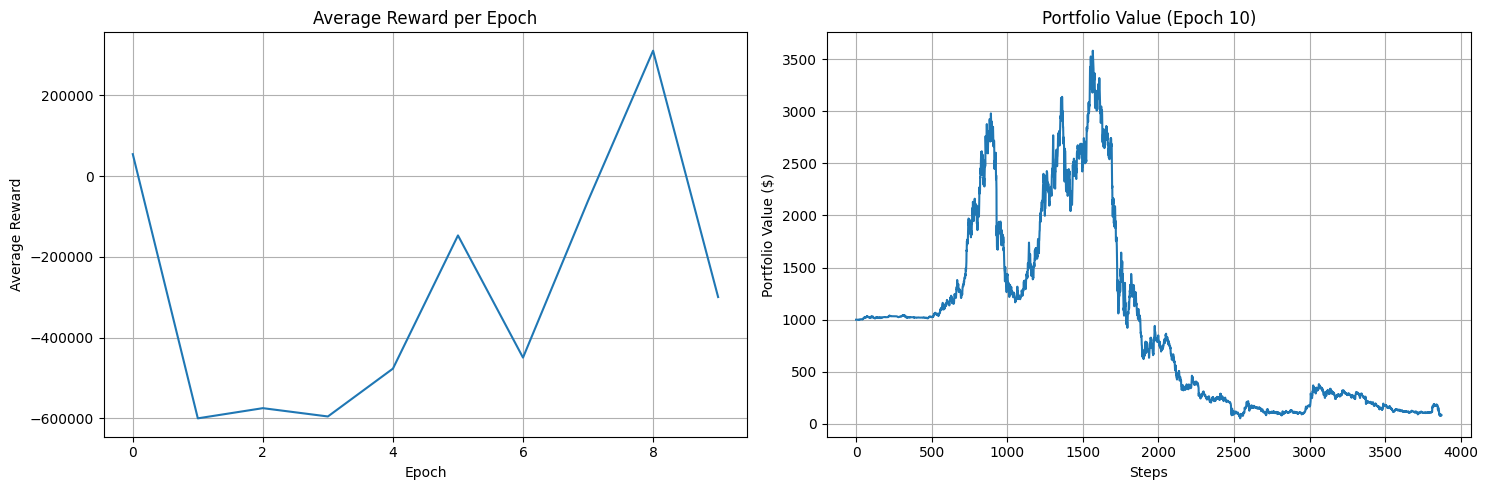

Epoch 10/10 - Average Reward: -299405.73


In [7]:
model, rewards, portfolios = train_agent(
    df,
    epochs=10,
    episodes_per_epoch=5,
    window_size=10,
    initial_balance=1000
)

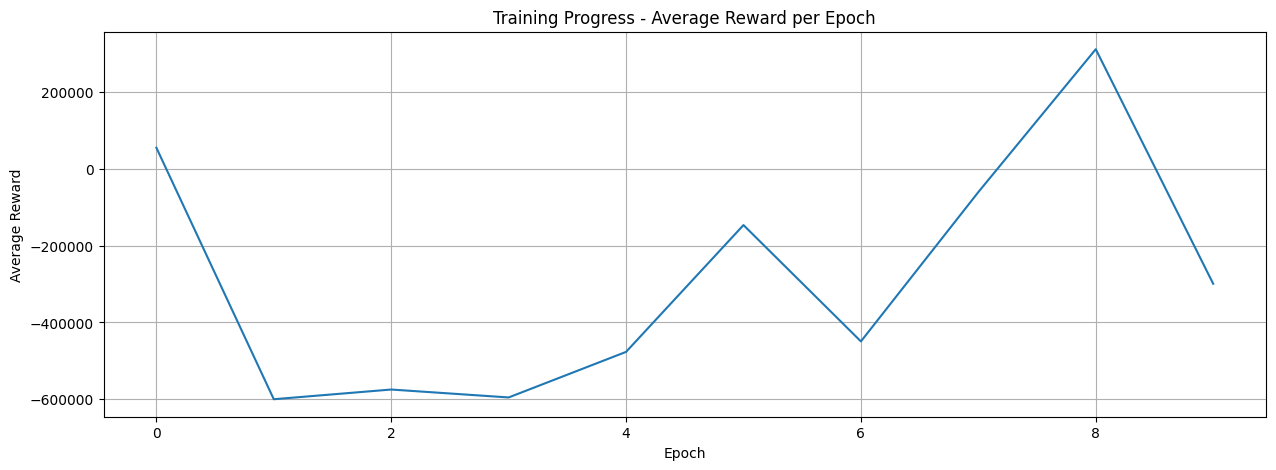

In [8]:
plt.figure(figsize=(15, 5))
plt.plot(rewards)
plt.title('Training Progress - Average Reward per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Average Reward')
plt.grid(True)
plt.show()

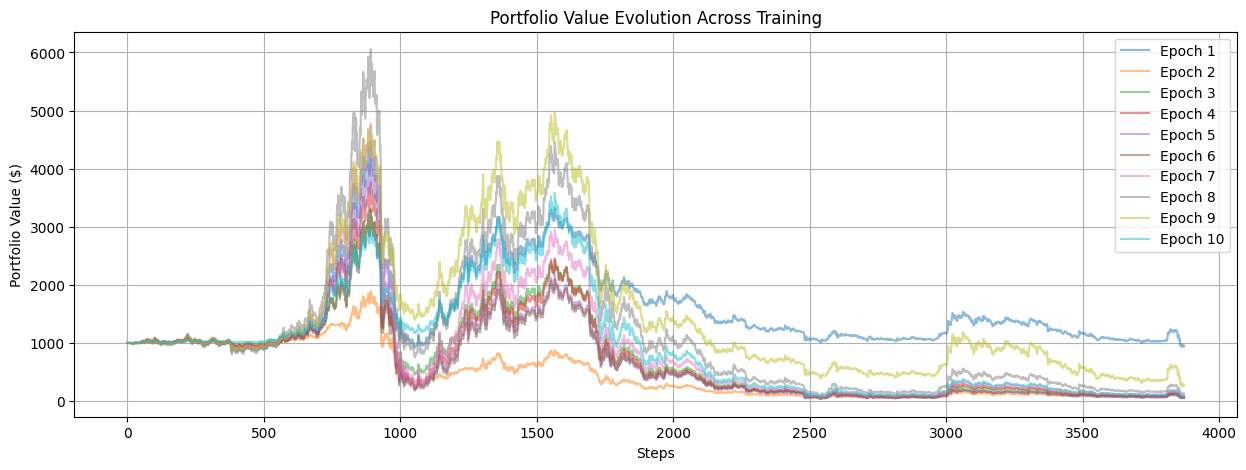

In [9]:
plt.figure(figsize=(15, 5))
for i, portfolio in enumerate(portfolios):
    plt.plot(portfolio, alpha=0.5, label=f'Epoch {i+1}')
plt.title('Portfolio Value Evolution Across Training')
plt.xlabel('Steps')
plt.ylabel('Portfolio Value ($)')
plt.legend()
plt.grid(True)
plt.show()